# Part 3c. Cosine similarity

Cosine similarity between two TF-IDF vectors is

\[
\cos(a, b) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}
\]

After L2 normalisation the vector lengths are 1, so the cosine equals the dot product. This notebook calculates that on the three-document example, then on real reviews: a 12-review similarity matrix, mean similarity inside a 300-review block, and the nearest neighbours of one low-score review and one high-score review.

## Setup, cleaning, and TF-IDF

In [1]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
if not (ROOT / "data" / "airlines_reviews.csv").exists():
    ROOT = Path(r"C:\Users\rdram\OneDrive\Desktop\Machine Learning\CA_machine_learning")

DATA_PATH = ROOT / "data" / "airlines_reviews.csv"
FIG = ROOT / "figures" / "cosine"
OUT = ROOT / "outputs" / "cosine"
FIG.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

RATING_COLS = [
    "Seat Comfort", "Staff Service", "Food & Beverages",
    "Inflight Entertainment", "Value For Money", "Overall Rating",
]
SERVICE_COLS = [
    "Seat Comfort", "Staff Service", "Food & Beverages", "Inflight Entertainment",
]
RANDOM_STATE = 42


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()


def silhouette_safe(X, labels):
    # Silhouette on non-noise points. NaN when a partition is not valid.
    labels = np.asarray(labels)
    mask = labels != -1
    y = labels[mask]
    if len(y) < 3 or len(np.unique(y)) < 2:
        return np.nan
    _, counts = np.unique(y, return_counts=True)
    if counts.min() < 2:
        return np.nan
    return float(silhouette_score(X[mask], y, n_jobs=-1))


print("Question folder:", FIG.parent.name + "/" + FIG.name)
print("Data file:", DATA_PATH)

Question folder: figures/cosine
Data file: C:\Users\rdram\OneDrive\Desktop\Machine Learning\CA_machine_learning\data\airlines_reviews.csv


In [2]:
raw = pd.read_csv(DATA_PATH)
df = raw.copy()
text_cols = [col for col in df.columns if pd.api.types.is_string_dtype(df[col])]
for col in text_cols:
    df[col] = df[col].str.replace("\xa0", " ", regex=False).str.strip()

verified_map = {
    "True": "True", "False": "False", "*Unverified*": "False", "NotVerified": "False",
}
n_verified_fixed = int((~df["Verified"].isin(["True", "False"])).sum())
df["Verified"] = df["Verified"].map(verified_map).fillna("False")

ife = df["Inflight Entertainment"]
n_ife_zero = int((ife == 0).sum())
ife_median = float(ife[ife > 0].median())
df.loc[ife == 0, "Inflight Entertainment"] = ife_median

n_dups = int(df["Reviews"].duplicated().sum())
df = df.drop_duplicates(subset=["Reviews"]).reset_index(drop=True)

df["Month Flown Date"] = pd.to_datetime(df["Month Flown"], format="%B %Y")
df["Year Flown"] = df["Month Flown Date"].dt.year
df["Year Bin"] = pd.cut(
    df["Year Flown"],
    bins=[2012, 2016, 2019, 2021, 2025],
    labels=["2013-2016", "2017-2019", "2020-2021", "2022-2024"],
).astype(str)
df["Review Length"] = df["Reviews"].str.len()

print(f"Rows before cleaning: {len(raw):,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Verified flags corrected: {n_verified_fixed}")
print(f"Inflight Entertainment zeros imputed with median {ife_median:.0f}: {n_ife_zero}")
print(f"Duplicate reviews removed: {n_dups}")

Rows before cleaning: 8,100
Rows after cleaning:  8,098
Verified flags corrected: 3
Inflight Entertainment zeros imputed with median 4: 1
Duplicate reviews removed: 2


In [3]:
def clean_text(text):
    text = text.replace("\xa0", " ").lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


df["review_clean"] = df["Reviews"].map(clean_text)
print("Empty reviews after cleaning:", int((df["review_clean"] == "").sum()))
print("Example:", df.loc[0, "review_clean"][:350])
TOKEN = r"(?u)\b[a-zA-Z]{2,}\b"
VECTOR_KW = dict(stop_words="english", token_pattern=TOKEN, min_df=5, max_df=0.85, max_features=3000)

Empty reviews after cleaning: 0
Example: flight was amazing the crew onboard this flight were very welcoming and gave a good atmosphere the crew serving my aisle goes by the initial g she was very kind helpful gave my mom a bday cake for a late celebration even though it was just a hr min flight seat is well sanitized legroom is spacious ife onboard has many variety of shows music etc bat


In [4]:
toy_docs = [
    "good food good service flight",
    "poor food rude service flight",
    "good food good crew flight",
]
toy_count = CountVectorizer(token_pattern=TOKEN)
tf_matrix = toy_count.fit_transform(toy_docs).toarray().astype(float)
n_docs = tf_matrix.shape[0]
df_t = (tf_matrix > 0).sum(axis=0)
idf = np.log((1 + n_docs) / (1 + df_t)) + 1
tfidf_raw = tf_matrix * idf
tfidf_norm = tfidf_raw / np.linalg.norm(tfidf_raw, axis=1, keepdims=True)

def cosine_pair(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

print("Toy cosine from the normalised vectors, checked with the formula on the raw TF-IDF vectors:")
for name_a, name_b, i, j in [("doc1", "doc2", 0, 1), ("doc1", "doc3", 0, 2), ("doc2", "doc3", 1, 2)]:
    dot = float(np.dot(tfidf_norm[i], tfidf_norm[j]))
    print(f"  cos({name_a}, {name_b}) = {dot:.4f}    formula = {cosine_pair(tfidf_raw[i], tfidf_raw[j]):.4f}")

tfidf_vec = TfidfVectorizer(**VECTOR_KW, norm="l2", smooth_idf=True)
X_tfidf = tfidf_vec.fit_transform(df["review_clean"])
print("Corpus TF-IDF shape:", X_tfidf.shape)

Toy cosine from the normalised vectors, checked with the formula on the raw TF-IDF vectors:
  cos(doc1, doc2) = 0.3721    formula = 0.3721
  cos(doc1, doc3) = 0.7936    formula = 0.7936
  cos(doc2, doc3) = 0.1925    formula = 0.1925


Corpus TF-IDF shape: (8098, 3000)


## Similarity matrix and neighbours

Cosine matrix for 6 low-score reviews, then 6 high-score reviews:


,Singapo:1,All:1,Japan:1,Air:1,Qatar:1,Cathay:2,Singapo:9,All:10,Japan:9,Air:9,Qatar:9,Cathay:9
Singapo:1,1.00,0.06,0.03,0.04,0.03,0.09,0.11,0.03,0.03,0.02,0.04,0.03
All:1,0.06,1.00,0.05,0.01,0.14,0.11,0.07,0.08,0.04,0.06,0.06,0.03
Japan:1,0.03,0.05,1.00,0.09,0.01,0.05,0.01,0.01,0.02,0.07,0.01,0.01
Air:1,0.04,0.01,0.09,1.00,0.00,0.02,0.02,0.00,0.02,0.11,0.02,0.03
Qatar:1,0.03,0.14,0.01,0.00,1.00,0.05,0.10,0.02,0.03,0.09,0.03,0.01
Cathay:2,0.09,0.11,0.05,0.02,0.05,1.00,0.04,0.00,0.03,0.02,0.01,0.05
Singapo:9,0.11,0.07,0.01,0.02,0.10,0.04,1.00,0.06,0.01,0.02,0.03,0.04
All:10,0.03,0.08,0.01,0.00,0.02,0.00,0.06,1.00,0.02,0.02,0.01,0.05
Japan:9,0.03,0.04,0.02,0.02,0.03,0.03,0.01,0.02,1.00,0.00,0.11,0.09
Air:9,0.02,0.06,0.07,0.11,0.09,0.02,0.02,0.02,0.00,1.00,0.02,0.03


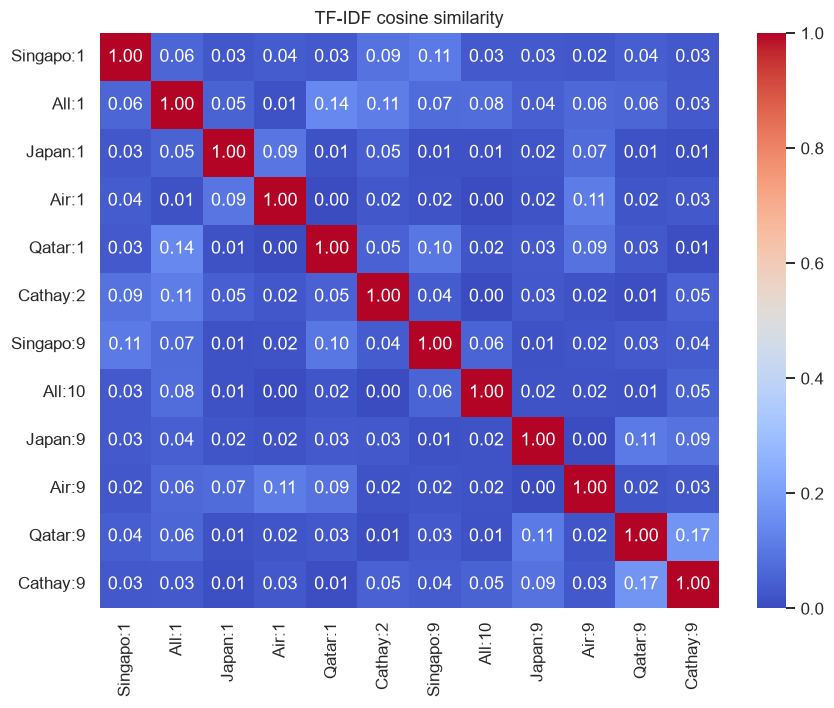

Mean cosine in a 300-review block (upper triangle):
  all pairs: 0.046
  both recommended: 0.055
  both not recommended: 0.047
  one of each: 0.040
Query 6669: Air France | Economy Class | overall 1 | recommended no
Malé to Paris CDG. Air France has overbooked our flight of 18 passengers. I was trying to understand what I had to do to fly and they all refused to talk to me at first. We were a lot of people waiting to be checked in. In the end, when I started complaining, they all answered “I don’t care I don’t work for Air France” indeed they were representative hired by Air France but none of their staff wer
Mean cosine to 200 random reviews: 0.047


,neighbor,cosine,airline,overall,recommended,snippet
0,6166,0.345,Air France,1,no,I have flown with Air France regularly because...
1,6110,0.335,Air France,1,no,We booked our flight through air France from T...
2,6818,0.327,Air France,2,no,Los Angeles to Paris CDG in Business Class in ...


Query 96: Singapore Airlines | First Class | overall 10 | recommended yes
Suites on the A380 are in terms of comfort and layout 100% better than on the SQ 777 although the high standard of service remains the same for both aircraft. Lovely welcome from the staff and the cabin crew are exceptionally well presented in grooming and demeanour.  I also am appreciative that I was addressed by my title and surname as I am of that older generation that appreciates such niceties
Mean cosine to 200 random reviews: 0.036


,neighbor,cosine,airline,overall,recommended,snippet
0,1036,0.239,Qatar Airways,10,yes,It was an absolutely lovely experience and the...
1,64,0.232,Singapore Airlines,10,yes,I have just flown SQ256 from Brisbane to Singa...
2,193,0.231,Singapore Airlines,9,yes,"Nice flights, first leg got Premium Economy se..."


In [5]:
def diverse_positions(frame, n, seed):
    picked = []
    for _, g in frame.groupby("Airline"):
        picked.append(int(g.sample(1, random_state=seed).index[0]))
    pool = frame.loc[picked]
    if len(pool) <= n:
        return pool.index.to_numpy()
    return pool.sample(n, random_state=seed).index.to_numpy()


low_pos = diverse_positions(df[df["Overall Rating"] <= 2], 6, RANDOM_STATE)
high_pos = diverse_positions(df[df["Overall Rating"] >= 9], 6, RANDOM_STATE)
heat_pos = np.concatenate([low_pos, high_pos])
S = cosine_similarity(X_tfidf[heat_pos])
heat_labels = [
    f"{df.loc[i, 'Airline'].split()[0][:7]}:{int(df.loc[i, 'Overall Rating'])}"
    for i in heat_pos
]
heat_df = pd.DataFrame(S, index=heat_labels, columns=heat_labels)
print("Cosine matrix for 6 low-score reviews, then 6 high-score reviews:")
display(heat_df.round(2))
heat_df.round(4).to_csv(OUT / "cosine_heatmap_12.csv")
fig, ax = plt.subplots(figsize=(8.2, 6.6))
sns.heatmap(heat_df, annot=True, fmt=".2f", cmap="coolwarm", vmin=0, vmax=1, ax=ax)
ax.set_title("TF-IDF cosine similarity")
save_fig(fig, "cosine_heatmap.png")

block_pos = df.sample(300, random_state=RANDOM_STATE).index.to_numpy()
S_block = cosine_similarity(X_tfidf[block_pos])
iu = np.triu_indices(len(block_pos), k=1)
rec_flag = df.loc[block_pos, "Recommended"].str.lower().eq("yes").to_numpy()
both_yes = rec_flag[:, None] & rec_flag[None, :]
both_no = (~rec_flag)[:, None] & (~rec_flag)[None, :]
mixed = rec_flag[:, None] ^ rec_flag[None, :]
print("Mean cosine in a 300-review block (upper triangle):")
print(f"  all pairs: {S_block[iu].mean():.3f}")
print(f"  both recommended: {S_block[iu][both_yes[iu]].mean():.3f}")
print(f"  both not recommended: {S_block[iu][both_no[iu]].mean():.3f}")
print(f"  one of each: {S_block[iu][mixed[iu]].mean():.3f}")


def show_neighbors(query_pos, n_neighbors=3):
    sims = cosine_similarity(X_tfidf[query_pos], X_tfidf).ravel()
    sims[query_pos] = -1
    order = np.argsort(sims)[::-1][:n_neighbors]
    rng = np.random.default_rng(RANDOM_STATE)
    candidates = np.delete(np.arange(len(df)), query_pos)
    baseline_idx = rng.choice(candidates, size=200, replace=False)
    baseline = float(cosine_similarity(X_tfidf[query_pos], X_tfidf[baseline_idx]).mean())
    q = df.loc[query_pos]
    print("=" * 80)
    print(
        f"Query {query_pos}: {q['Airline']} | {q['Class']} | overall {q['Overall Rating']} | recommended {q['Recommended']}"
    )
    print(q["Reviews"][:400].replace("\n", " "))
    print(f"Mean cosine to 200 random reviews: {baseline:.3f}")
    rows = []
    for j in order:
        other = df.loc[int(j)]
        rows.append({
            "neighbor": int(j),
            "cosine": float(sims[j]),
            "airline": other["Airline"],
            "overall": int(other["Overall Rating"]),
            "recommended": other["Recommended"],
            "snippet": other["Reviews"][:180].replace("\n", " "),
        })
    display(pd.DataFrame(rows).round(3))


low_query = int(df[df["Overall Rating"] == 1].sample(1, random_state=RANDOM_STATE).index[0])
high_query = int(df[df["Overall Rating"] == 10].sample(1, random_state=RANDOM_STATE).index[0])
show_neighbors(low_query)
show_neighbors(high_query)

## Part 3c answer

On the toy documents, the two "good" reviews have the higher cosine, and the formula matches the normalised dot product. On the corpus, the 12 by 12 heatmap is the similarity matrix for a readable sample. The 300-review means summarise whether recommended reviews are slightly closer to each other than to reviews with the opposite recommendation. Each neighbour list should sit above that query's mean cosine to 200 random reviews.